<a href="https://colab.research.google.com/github/mariemehab/predictive-maintenance-ml/blob/main/Predictive_Maintenance_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd


In [2]:
df=pd.read_csv("ai4i2020.csv")

In [3]:
df


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [4]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [6]:
df.shape   #(no of row, no of coloumn)

(10000, 14)

In [7]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [9]:
df.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [10]:
df["Machine failure"].value_counts()

,count
Machine failure,
0,9661
1,339


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

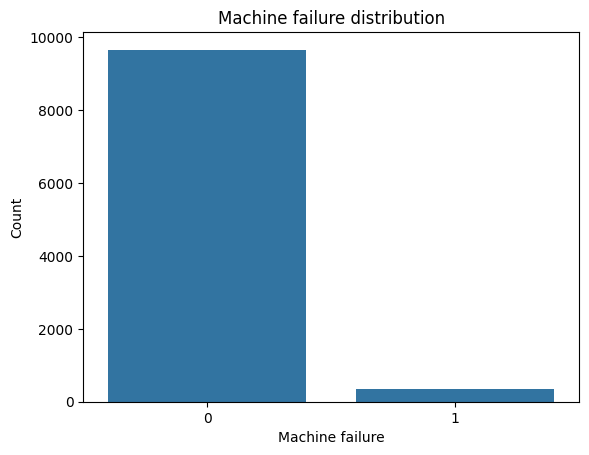

In [12]:
sns.countplot(data=df , x="Machine failure")
plt.title("Machine failure distribution")
plt.xlabel("Machine failure")
plt.ylabel("Count")
plt.show()

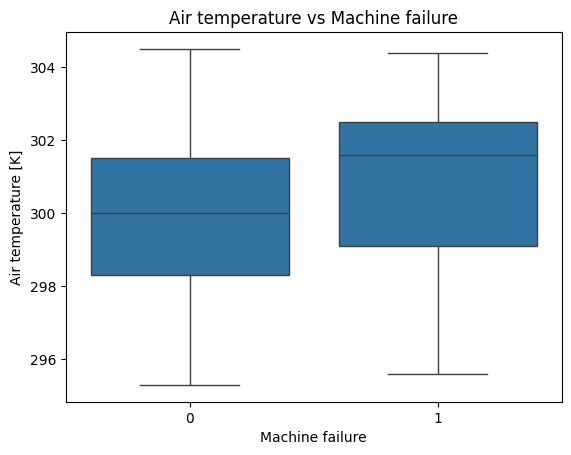

In [15]:
sns.boxplot(
    data=df,
    x="Machine failure",
    y="Air temperature [K]"

)
plt.title("Air temperature vs Machine failure")
plt.show()

In [16]:
df.groupby("Machine failure")["Air temperature [K]"].describe()

,count,mean,std,min,25%,50%,75%,max
Machine failure,,,,,,,,
0,9661.0,299.973999,1.990748,295.3,298.3,300.0,301.5,304.5
1,339.0,300.886431,2.071473,295.6,299.1,301.6,302.5,304.4


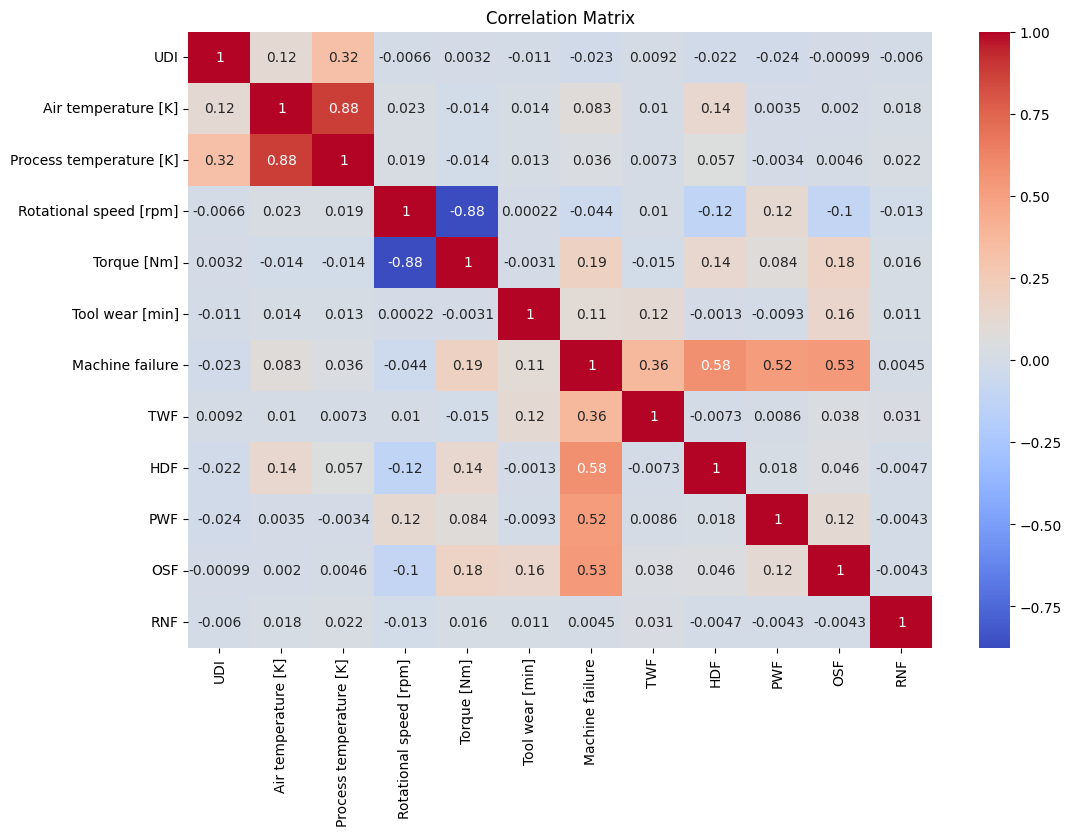

In [18]:
numeric_df = df.select_dtypes(include="number")
corr_matrix = numeric_df.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()


In [19]:

features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[features]
y = df["Machine failure"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (10000, 6)
y shape: (10000,)


In [21]:
from sklearn.model_selection import train_test_split
X_train,x_temp,y_train,y_temp=train_test_split(X,y,test_size=0.4,random_state=42,stratify=y)
X_val,X_test,y_val,y_test=train_test_split(x_temp,y_temp,test_size=0.5,random_state=42,stratify=y_temp    )

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)



Train: (6000, 6)
Validation: (2000, 6)
Test: (2000, 6)


In [22]:

print("Training:")
print(y_train.value_counts(normalize=True))

print("Validation:")
print(y_val.value_counts(normalize=True))

print("Testing:")
print(y_test.value_counts(normalize=True))


Training:
Machine failure
0    0.966167
1    0.033833
Name: proportion, dtype: float64
Validation:
Machine failure
0    0.966
1    0.034
Name: proportion, dtype: float64
Testing:
Machine failure
0    0.966
1    0.034
Name: proportion, dtype: float64


In [23]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numerical_features)
    ]
)


In [24]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [26]:
X_train.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
3736,H,302.2,311.1,1628,30.6,105
8772,L,297.5,308.6,1621,28.9,0
6622,L,301.7,310.7,1493,51.1,87
9000,L,297.0,307.9,1493,46.1,173
7604,L,300.4,311.3,1639,34.6,24


In [27]:

X_train_transformed = preprocessor.fit_transform(X_train)


In [28]:


feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_train.index
)

X_train_processed.head()


,cat__Type_H,cat__Type_L,cat__Type_M,num__Air temperature [K],num__Process temperature [K],num__Rotational speed [rpm],num__Torque [Nm],num__Tool wear [min]
3736,1.0,0.0,0.0,1.087844,0.735168,0.493757,-0.940123,-0.039216
8772,0.0,1.0,0.0,-1.257275,-0.954692,0.454979,-1.109531,-1.691034
6622,0.0,1.0,0.0,0.838364,0.464790,-0.254103,1.102741,-0.322385
9000,0.0,1.0,0.0,-1.506756,-1.427853,-0.254103,0.604482,1.030532
7604,0.0,1.0,0.0,0.189714,0.870357,0.554693,-0.541515,-1.313476


In [29]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

baseline_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type']),
                                                 ('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]'])])),
                ('model', LogisticRegression(max_iter=2000))])

In [30]:

from sklearn.metrics import classification_report, confusion_matrix

y_val_pred = baseline_model.predict(X_val)

print(classification_report(
    y_val,
    y_val_pred,
    zero_division=0
))

print(confusion_matrix(y_val, y_val_pred))


              precision    recall  f1-score   support

           0       0.97      1.00      0.99      1932
           1       0.73      0.24      0.36        68

    accuracy                           0.97      2000
   macro avg       0.85      0.62      0.67      2000
weighted avg       0.97      0.97      0.96      2000

[[1926    6]
 [  52   16]]


In [31]:

balanced_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

balanced_model.fit(X_train, y_train)

y_balanced_pred = balanced_model.predict(X_val)

print(classification_report(
    y_val,
    y_balanced_pred,
    zero_division=0
))

print(confusion_matrix(y_val, y_balanced_pred))


              precision    recall  f1-score   support

           0       0.99      0.84      0.91      1932
           1       0.15      0.79      0.25        68

    accuracy                           0.84      2000
   macro avg       0.57      0.82      0.58      2000
weighted avg       0.96      0.84      0.89      2000

[[1628  304]
 [  14   54]]


In [32]:


y_val_proba = baseline_model.predict_proba(X_val)[:, 1]

print(y_val_proba[:10])


[0.00604877 0.00126363 0.00561782 0.00496696 0.0533501  0.15008516
 0.52962645 0.02282843 0.00127169 0.00951144]


In [33]:

threshold = 0.3

y_pred_new = (y_val_proba >= threshold).astype(int)

print(classification_report(
    y_val,
    y_pred_new,
    zero_division=0
))

print(confusion_matrix(y_val, y_pred_new))


              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1932
           1       0.49      0.32      0.39        68

    accuracy                           0.97      2000
   macro avg       0.73      0.66      0.69      2000
weighted avg       0.96      0.97      0.96      2000

[[1909   23]
 [  46   22]]


In [34]:

from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

for t in thresholds:
    predictions = (y_val_proba >= t).astype(int)

    print(
        "Threshold:", t,
        "Precision:", round(precision_score(y_val, predictions, zero_division=0), 3),
        "Recall:", round(recall_score(y_val, predictions, zero_division=0), 3),
        "F1:", round(f1_score(y_val, predictions, zero_division=0), 3)
    )


Threshold: 0.1 Precision: 0.274 Recall: 0.588 F1: 0.374
Threshold: 0.2 Precision: 0.397 Recall: 0.426 F1: 0.411
Threshold: 0.3 Precision: 0.489 Recall: 0.324 F1: 0.389
Threshold: 0.4 Precision: 0.581 Recall: 0.265 F1: 0.364
Threshold: 0.5 Precision: 0.727 Recall: 0.235 F1: 0.356
